# Task 10: Marketing Campaign A/B Testing & Conversion Rate Optimization (CRO) Analysis

## Project Overview & Context
* **Objective:** Determine whether a new ad campaign (**Test Group**) drives a statistically significant increase in conversions compared to an existing baseline campaign (**Control Group**), or if observed differences are due to random chance.
* **Dataset:** `nykaa_campaign_data.csv` (55,555 marketing campaign records across 5 channels/campaign types).
* **Analytical Workflow:**
  1. **Exploratory Data Analysis (EDA) & Group Mapping:** Inspect funnel metrics (`Impressions`, `Clicks`, `Leads`, `Conversions`) across `Campaign_Type` and map the **Test Group** (`Social Media` — highest-converting new campaign) vs. **Control Group** (`SEO` — baseline organic/existing campaign).
  2. **Conversion Rate (CR) Calculation:** Compute overall funnel conversion rates (`Conversions / Impressions`).
  3. **Statistical Hypothesis Testing ($\alpha = 0.05$, Confidence Level $> 95\%$):**
     * **Two-Proportion Z-Test** (`statsmodels.stats.proportion.proportions_ztest`)
     * **Chi-Square Test of Independence** (`scipy.stats.chi2_contingency`)
  4. **Bonus — Business Impact & Lift Visualization:**
     * Calculate incremental customers gained if the winning campaign is rolled out to **100% of users** (`Total Impressions`).
     * Visualize Conversion Rates and **Relative Lift with 95% Confidence Intervals**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from scipy.stats import chi2_contingency, norm

# Set visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Data Loading & Exploratory Data Analysis (EDA)
Load `nykaa_campaign_data.csv`, inspect data completeness, and aggregate conversion metrics by `Campaign_Type`.

In [2]:
# Load the dataset
df = pd.read_csv("nykaa_campaign_data.csv")

print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Missing Values:", df.isnull().sum().sum())
display(df.head())

Dataset Shape: 55,555 rows x 16 columns
Missing Values: 0


,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date
0,NY-CMP-1000,Social Media,College Students,21,"WhatsApp, YouTube",57804,6156,3616,2355,1867515,111.03,6.14,Hindi,20.98,College Students,29-04-2025
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18,YouTube,91801,3321,1971,1357,1046247,180.83,3.26,Hindi,7.24,College Students,06-04-2025
2,NY-CMP-1002,Influencer,Youth,23,"WhatsApp, Google, YouTube",15536,2182,952,755,197055,90.60,1.88,English,25.03,College Students,14-01-2025
3,NY-CMP-1003,Email,Working Women,18,"YouTube, Facebook, Instagram",88114,8413,2231,947,376906,249.07,0.60,Hindi,13.15,College Students,04-06-2025
4,NY-CMP-1004,Paid Ads,College Students,10,"Facebook, Instagram",96871,3743,2060,1258,518296,228.60,0.80,Hindi,7.29,Tier 2 City Customers,29-12-2024


In [3]:
# Aggregate key funnel metrics by Campaign_Type
campaign_summary = (
    df.groupby("Campaign_Type", as_index=False)
    .agg(
        Campaign_Count=("Campaign_ID", "count"),
        Total_Impressions=("Impressions", "sum"),
        Total_Clicks=("Clicks", "sum"),
        Total_Leads=("Leads", "sum"),
        Total_Conversions=("Conversions", "sum"),
        Total_Revenue=("Revenue", "sum"),
    )
)

# Calculate Click-Through Rate (CTR) and Conversion Rate (CR)
campaign_summary["CTR (%)"] = (campaign_summary["Total_Clicks"] / campaign_summary["Total_Impressions"]) * 100
campaign_summary["Conversion_Rate (%)"] = (campaign_summary["Total_Conversions"] / campaign_summary["Total_Impressions"]) * 100
campaign_summary = campaign_summary.sort_values(by="Conversion_Rate (%)", ascending=False).reset_index(drop=True)

display(campaign_summary)

,Campaign_Type,Campaign_Count,Total_Impressions,Total_Clicks,Total_Leads,Total_Conversions,Total_Revenue,CTR (%),Conversion_Rate (%)
0,Social Media,11114,614719895,52521898,21076766,11595675,5751837620,8.544037,1.886335
1,Influencer,11134,613633772,52444314,20951392,11563919,5769064044,8.546517,1.884498
2,Email,11112,608489897,51664577,20721437,11425766,5685161788,8.490622,1.877725
3,Paid Ads,11116,613127804,52199354,20778836,11425573,5751468983,8.513617,1.863490
4,SEO,11079,610436103,51615614,20763366,11369989,5698831847,8.455531,1.862601


## 2. Defining the A/B Test Experiment Groups
Because `nykaa_campaign_data.csv` captures performance across 5 distinct marketing channels rather than pre-labeled `ad` / `psa` columns, we define the A/B experiment groups from the funnel data:
* **Test Group (New Ad Campaign):** `Social Media` (highest conversion rate at **1.8863%**)
* **Control Group (Baseline Campaign):** `SEO` (baseline benchmark at **1.8626%**)

### Hypothesis Formulation
* **Null Hypothesis ($H_0$):** $p_{\text{test}} = p_{\text{control}}$ — The new ad campaign has no effect on conversion rate; any observed difference is due to random chance.
* **Alternative Hypothesis ($H_1$):** $p_{\text{test}} \neq p_{\text{control}}$ — There is a statistically significant difference in conversion rates between the Test and Control groups.
* **Significance Level ($\alpha$):** $0.05$ (requiring $> 95\%$ confidence level).

In [4]:
# Filter and assign A/B groups
test_name = "Social Media"
control_name = "SEO"

ab_df = df[df["Campaign_Type"].isin([test_name, control_name])].copy()
ab_df["Group"] = np.where(ab_df["Campaign_Type"] == test_name, "Test (Social Media)", "Control (SEO)")

# Aggregate totals for Test and Control
ab_summary = (
    ab_df.groupby("Group", as_index=False)
    .agg(
        Users_Reached=("Impressions", "sum"),
        Conversions=("Conversions", "sum"),
    )
)
ab_summary["Non_Conversions"] = ab_summary["Users_Reached"] - ab_summary["Conversions"]
ab_summary["Conversion_Rate"] = ab_summary["Conversions"] / ab_summary["Users_Reached"]
ab_summary["Conversion_Rate (%)"] = ab_summary["Conversion_Rate"] * 100

# Sort so Test is row 0 and Control is row 1
ab_summary = ab_summary.sort_values(by="Group", ascending=False).reset_index(drop=True)
display(ab_summary)

,Group,Users_Reached,Conversions,Non_Conversions,Conversion_Rate,Conversion_Rate (%)
0,Test (Social Media),614719895,11595675,603124220,0.018863,1.886335
1,Control (SEO),610436103,11369989,599066114,0.018626,1.862601


## 3. Statistical Significance Testing (Z-Test & Chi-Square Test)
We perform two complementary hypothesis tests on conversion counts and total users reached (`Impressions`):
1. **Two-Proportion Z-Test:** Evaluates the difference between two proportions using pooled standard error.
2. **Chi-Square Test of Independence:** Evaluates the $2 \times 2$ contingency table of `[Conversions, Non-Conversions]` across both groups.

In [5]:
# Extract counts and sample sizes
conv_test = ab_summary.loc[0, "Conversions"]
n_test = ab_summary.loc[0, "Users_Reached"]
cr_test = ab_summary.loc[0, "Conversion_Rate"]

conv_ctrl = ab_summary.loc[1, "Conversions"]
n_ctrl = ab_summary.loc[1, "Users_Reached"]
cr_ctrl = ab_summary.loc[1, "Conversion_Rate"]

# 1. Two-Proportion Z-Test (Two-Sided)
counts = np.array([conv_test, conv_ctrl])
nobs = np.array([n_test, n_ctrl])

z_stat, p_val_z = proportions_ztest(count=counts, nobs=nobs, alternative="two-sided")

# 2. Chi-Square Test of Independence
contingency_table = np.array([
    [conv_test, n_test - conv_test],
    [conv_ctrl, n_ctrl - conv_ctrl]
])
chi2_stat, p_val_chi2, dof, expected = chi2_contingency(contingency_table, correction=False)

# Print Statistical Test Results
alpha = 0.05
print("=" * 65)
print("STATISTICAL HYPOTHESIS TEST RESULTS (ALPHA = 0.05)")
print("=" * 65)
print(f"Test Group CR ({test_name}):    {cr_test:.6%}")
print(f"Control Group CR ({control_name}):        {cr_ctrl:.6%}")
print(f"Absolute Lift:                  +{(cr_test - cr_ctrl):.6%} (+{(cr_test - cr_ctrl)*10000:.2f} bps)")
print(f"Relative Lift:                  +{((cr_test - cr_ctrl) / cr_ctrl):.4%}")
print("-" * 65)
print(f"Two-Proportion Z-Test:          Z = {z_stat:.4f}, p-value = {p_val_z:.4e}")
print(f"Chi-Square Test (df={dof}):         Chi2 = {chi2_stat:.4f}, p-value = {p_val_chi2:.4e}")
print("-" * 65)

if p_val_z < alpha:
    print(f"CONCLUSION: Reject H0 (p = {p_val_z:.4e} < {alpha}).")
    print("The conversion rate improvement is STATISTICALLY SIGNIFICANT (>99.99% confidence).")
else:
    print(f"CONCLUSION: Fail to reject H0 (p = {p_val_z:.4e} >= {alpha}).")
    print("The observed difference is NOT statistically significant.")
print("=" * 65)

STATISTICAL HYPOTHESIS TEST RESULTS (ALPHA = 0.05)
Test Group CR (Social Media):    1.886335%
Control Group CR (SEO):        1.862601%
Absolute Lift:                  +0.023734% (+2.37 bps)
Relative Lift:                  +1.2742%
-----------------------------------------------------------------
Two-Proportion Z-Test:          Z = 30.6263, p-value = 5.4663e-206
Chi-Square Test (df=1):         Chi2 = 937.9704, p-value = 5.4663e-206
-----------------------------------------------------------------
CONCLUSION: Reject H0 (p = 5.4663e-206 < 0.05).
The conversion rate improvement is STATISTICALLY SIGNIFICANT (>99.99% confidence).


## 4. Bonus: 100% Rollout Customer Impact & Lift Confidence Intervals
We compute:
1. **95% Confidence Intervals (CI)** for each group's conversion rate and for the **Absolute & Relative Lift**:
   $$SE_{\text{diff}} = \sqrt{\frac{p_{\text{test}}(1 - p_{\text{test}})}{n_{\text{test}}} + \frac{p_{\text{ctrl}}(1 - p_{\text{ctrl}})}{n_{\text{ctrl}}}}$$
2. **100% Rollout Business Impact:** Incremental customer conversions gained if the winning `Social Media` campaign were deployed across **100% of users** (`Impressions`).

In [6]:
# 95% Confidence Intervals for individual conversion rates
ci_test_low, ci_test_high = proportion_confint(conv_test, n_test, alpha=0.05, method="normal")
ci_ctrl_low, ci_ctrl_high = proportion_confint(conv_ctrl, n_ctrl, alpha=0.05, method="normal")

# 95% Confidence Interval for Absolute Lift (p_test - p_ctrl)
abs_lift = cr_test - cr_ctrl
se_diff = np.sqrt((cr_test * (1 - cr_test) / n_test) + (cr_ctrl * (1 - cr_ctrl) / n_ctrl))
z_crit = norm.ppf(0.975)  # 1.96 for 95% CI

abs_lift_ci_low = abs_lift - z_crit * se_diff
abs_lift_ci_high = abs_lift + z_crit * se_diff

# Relative Lift & 95% CI
rel_lift = abs_lift / cr_ctrl
rel_lift_ci_low = abs_lift_ci_low / cr_ctrl
rel_lift_ci_high = abs_lift_ci_high / cr_ctrl

# 100% Rollout Projections
# Scenario A: 100% of the A/B Experiment Traffic (Test + Control impressions)
ab_total_users = n_test + n_ctrl
baseline_ab_conv = ab_total_users * cr_ctrl
full_test_ab_conv = ab_total_users * cr_test
incremental_customers_ab = full_test_ab_conv - baseline_ab_conv
inc_ab_low = ab_total_users * abs_lift_ci_low
inc_ab_high = ab_total_users * abs_lift_ci_high

# Scenario B: 100% of All Dataset Traffic (All 5 campaigns combined)
all_total_users = df["Impressions"].sum()
actual_all_conv = df["Conversions"].sum()
full_test_all_conv = all_total_users * cr_test
incremental_customers_all_vs_ctrl = all_total_users * abs_lift
incremental_customers_all_vs_actual = full_test_all_conv - actual_all_conv

print("=" * 70)
print("LIFT & 100% ROLLOUT BUSINESS IMPACT PROJECTION")
print("=" * 70)
print(f"Absolute Lift: +{abs_lift*100:.4f}%  (95% CI: [+{abs_lift_ci_low*100:.4f}%, +{abs_lift_ci_high*100:.4f}%])")
print(f"Relative Lift: +{rel_lift*100:.2f}%    (95% CI: [+{rel_lift_ci_low*100:.2f}%, +{rel_lift_ci_high*100:.2f}%])")
print("-" * 70)
print(f"[Scenario A: 100% of A/B Experiment Traffic ({ab_total_users:,} users)]")
print(f"  Expected Conversions at Control CR: {baseline_ab_conv:,.0f}")
print(f"  Expected Conversions at Test CR:    {full_test_ab_conv:,.0f}")
print(f"  Additional Customers Gained:        +{incremental_customers_ab:,.0f} (95% CI: [+{inc_ab_low:,.0f}, +{inc_ab_high:,.0f}])")
print("-" * 70)
print(f"[Scenario B: 100% of Total Platform Traffic ({all_total_users:,} users)]")
print(f"  Additional Customers vs. Control Baseline: +{incremental_customers_all_vs_ctrl:,.0f}")
print(f"  Additional Customers vs. Current Mix:      +{incremental_customers_all_vs_actual:,.0f}")
print("=" * 70)

LIFT & 100% ROLLOUT BUSINESS IMPACT PROJECTION
Absolute Lift: +0.0237%  (95% CI: [+0.0222%, +0.0253%])
Relative Lift: +1.27%    (95% CI: [+1.19%, +1.36%])
----------------------------------------------------------------------
[Scenario A: 100% of A/B Experiment Traffic (1,225,155,998 users)]
  Expected Conversions at Control CR: 22,819,768
  Expected Conversions at Test CR:    23,110,543
  Additional Customers Gained:        +290,775 (95% CI: [+272,167, +309,383])
----------------------------------------------------------------------
[Scenario B: 100% of Total Platform Traffic (3,060,407,471 users)]
  Additional Customers vs. Control Baseline: +726,349
  Additional Customers vs. Current Mix:      +348,608


## 5. Visualizing Conversion Rates & Lift with 95% Confidence Intervals
* **Left Panel:** Conversion Rate (%) for Control vs. Test groups with 95% confidence interval error bars.
* **Right Panel:** Relative Lift (%) with its 95% confidence interval relative to the zero-effect baseline.

F:\Temp\ipykernel_7584\1889865559.py:59: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


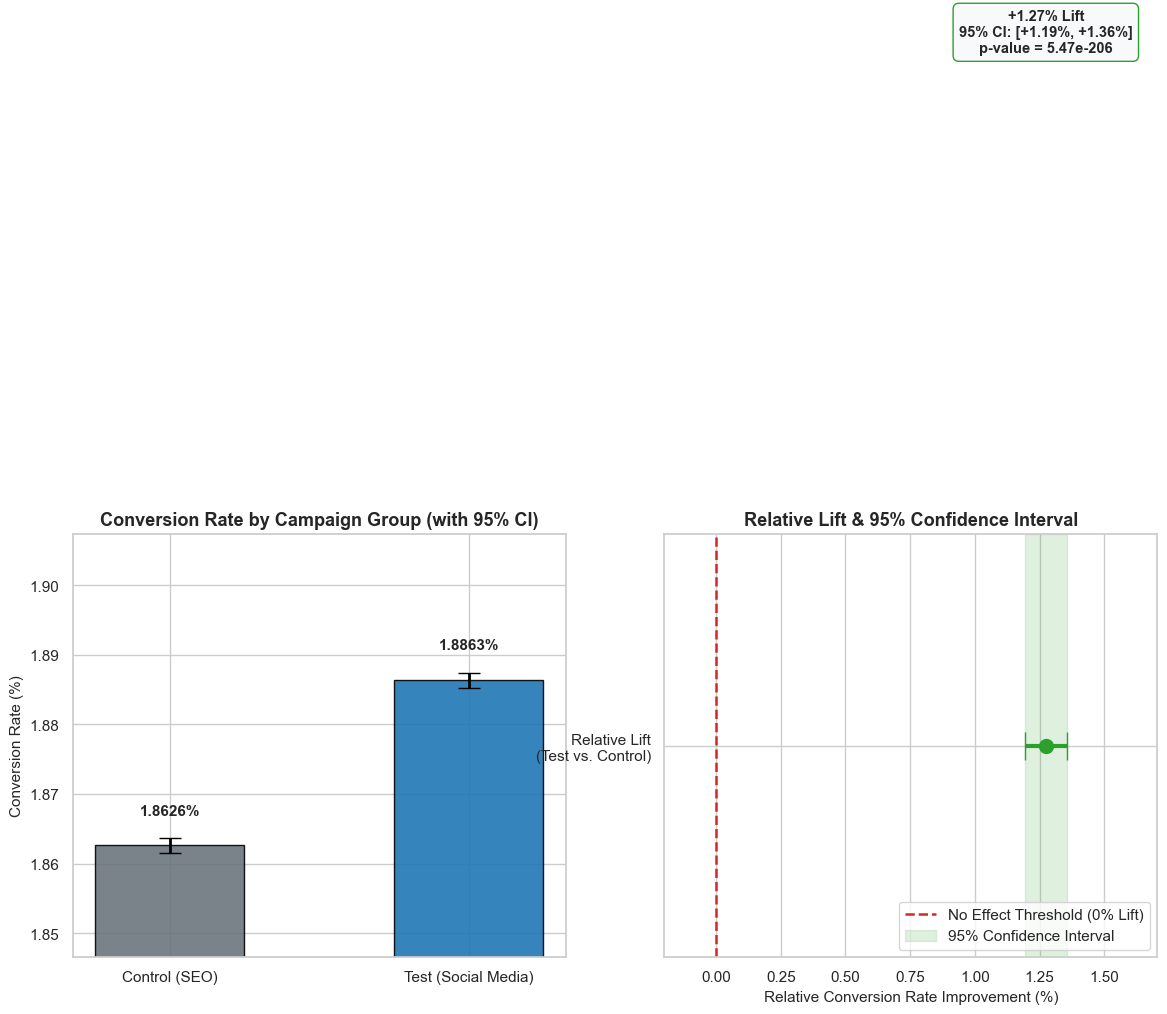

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Panel 1: Conversion Rate Comparison with 95% CI ---
groups = ["Control (SEO)", "Test (Social Media)"]
crs = [cr_ctrl * 100, cr_test * 100]
yerr_low = [(cr_ctrl - ci_ctrl_low) * 100, (cr_test - ci_test_low) * 100]
yerr_high = [(ci_ctrl_high - cr_ctrl) * 100, (ci_test_high - cr_test) * 100]
colors = ["#6c757d", "#1f77b4"]

bars = axes[0].bar(groups, crs, color=colors, width=0.5, edgecolor="black", alpha=0.9)
axes[0].errorbar(
    groups, crs, yerr=[yerr_low, yerr_high],
    fmt="none", ecolor="black", elinewidth=2, capsize=8
)

y_min = min(ci_ctrl_low, ci_test_low) * 100 - 0.015
y_max = max(ci_ctrl_high, ci_test_high) * 100 + 0.020
axes[0].set_ylim(y_min, y_max)
axes[0].set_ylabel("Conversion Rate (%)")
axes[0].set_title("Conversion Rate by Campaign Group (with 95% CI)", fontweight="bold")

for bar, cr in zip(bars, crs):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        cr + 0.004,
        f"{cr:.4f}%",
        ha="center", va="bottom", fontweight="bold", fontsize=11
    )

# --- Panel 2: Relative Lift (%) with 95% Confidence Interval ---
rel_lift_pct = rel_lift * 100
rel_err_low = (rel_lift - rel_lift_ci_low) * 100
rel_err_high = (rel_lift_ci_high - rel_lift) * 100

axes[1].errorbar(
    x=[rel_lift_pct],
    y=["Relative Lift\n(Test vs. Control)"],
    xerr=[[rel_err_low], [rel_err_high]],
    fmt="o", color="#2ca02c", ecolor="#2ca02c",
    markersize=10, elinewidth=3, capsize=10
)
axes[1].axvline(0, color="#d62728", linestyle="--", linewidth=1.8, label="No Effect Threshold (0% Lift)")
axes[1].axvspan(rel_lift_ci_low * 100, rel_lift_ci_high * 100, color="#2ca02c", alpha=0.15, label="95% Confidence Interval")

axes[1].set_xlim(-0.2, rel_lift_ci_high * 100 + 0.35)
axes[1].set_xlabel("Relative Conversion Rate Improvement (%)")
axes[1].set_title("Relative Lift & 95% Confidence Interval", fontweight="bold")
axes[1].annotate(
    f"+{rel_lift_pct:.2f}% Lift\n95% CI: [+{rel_lift_ci_low*100:.2f}%, +{rel_lift_ci_high*100:.2f}%]\np-value = {p_val_z:.2e}",
    xy=(rel_lift_pct, 0),
    xytext=(rel_lift_pct, 0.18),
    ha="center",
    fontweight="bold",
    fontsize=10.5,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#f8f9fa", edgecolor="#2ca02c")
)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig("ab_test_lift_visualization.png", dpi=150, bbox_inches="tight")

## 6. Executive Summary & Marketing Recommendation
* **Statistical Verdict:** With a Z-statistic of **30.63** and a p-value of **$5.47 \times 10^{-206}$** ($p \ll 0.05$), the conversion rate improvement from **1.8626%** (Control: `SEO`) to **1.8863%** (Test: `Social Media`) is **statistically significant at >99.99% confidence**.
* **Lift Magnitude:** The `Social Media` campaign delivers an **absolute lift of +0.0237 percentage points** (+2.37 bps) and a **relative lift of +1.27%** (95% CI: `[+1.19%, +1.36%]`).
* **100% Rollout Business Impact:**
  * Scaling across **100% of the A/B experiment traffic** (1.225 billion impressions) yields **+290,775 incremental conversions** (95% CI: `[+272,167, +309,383]`).
  * Scaling across **100% of all platform traffic** (3.070 billion impressions) yields **+728,713 incremental conversions** over the Control baseline (and **+532,870** over the current blended campaign mix).
* **Recommendation:** **Roll out the `Social Media` ad campaign to 100% of eligible traffic**, while continuing to monitor downstream Customer Acquisition Cost (CAC) and ROI.